# Лабораторная работа №2
## Интервенция в граф уравнений Навье — Стокса

Вариант Дмитрия **2–1–2**: ковариации параметров и риманова геометрия, зануление наблюдаемой переменной, KL-дивергенция.

Взята модель Ивана из [NavieStocks_project](https://github.com/papayiv/NavieStocks_project/tree/66eb7bc73cd802a3249c058ad69fc59a95fbd807). Исходный модуль графа сохранён в `src/navier_lab/ivan_graph.py` без изменений. Считаем коэффициенты той же системы и проверяем ветви давления.

**Вопрос опыта:** можно ли убрать давление из графа, если после зануления заново оценить остальные коэффициенты? Для ответа сравним ошибку и распределения оценок параметров. Это черновик к обсуждению: в конце отдельно указаны вопросы о внешних данных и выбранной геометрии.

In [1]:
import json
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
ROOT = Path.cwd() if (Path.cwd()/"src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT/"src"))
from navier_lab.data import load_cylinder
from navier_lab.model import momentum_from_fields, taylor_green, fit_blocks
from navier_lab.experiment import run_experiment, json_result
from navier_lab.geometry import estimate_gaussian, gaussian_kl
from navier_lab.ivan_graph import build_navier_stokes_2d
from navier_lab.plotting import (plot_model_graph, plot_fields, plot_distributions,
                                 plot_sensitivity, plot_covariance_geometry)
OUTPUT = ROOT/"results"/"lab2"
OUTPUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"font.family":"DejaVu Sans", "font.size":10,
                     "axes.spines.top":False, "axes.spines.right":False})

## 1. Модель и параметры

Для несжимаемой жидкости с постоянной плотностью $\rho=1$ и без внешней силы:

$$
u_t+\beta(uu_x+vu_y)=-p_x+\nu(u_{xx}+u_{yy}),
$$

$$
v_t+\beta(uv_x+vv_y)=-p_y+\nu(v_{xx}+v_{yy}),\qquad u_x+v_y=0.
$$

Здесь $u,v$ — скорости, $p$ — давление, а вектор оцениваемых параметров $\theta=(\beta,\nu)$. Ожидаемые значения: **β=1, ν=0,01**. В исходном графе коэффициент конвекции равен единице. Мы явно выносим его в β, чтобы видеть, как модель компенсирует удаление давления. Такая параметризация используется и в статье Raissi et al. (2019). Плотность не подбираем: она фиксирует масштаб давления.

ν соответствует узлу вязкости исходного графа и двум его связям с лапласианами. β задаёт общий вес двух ветвей конвекции. Интервенция затрагивает наблюдаемый узел p и его рёбра к операциям $\partial_x p$, $\partial_y p$. На рисунке несколько операций исходного DAG собраны в группы.

Исходный граф: 42 узлов
Узел давления: 2 ; его рёбра: [(2, 16, 'd/dx'), (2, 31, 'd/dy')]
Узел вязкости: 4


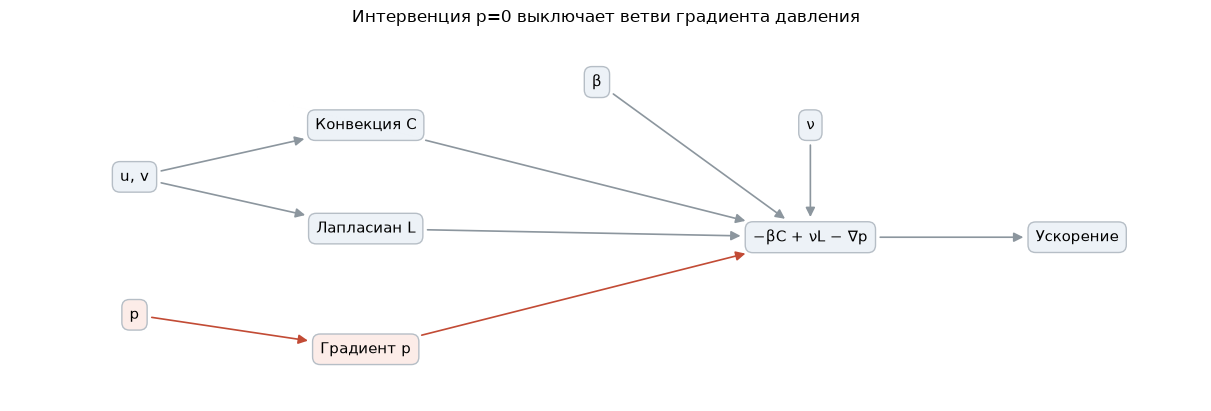

In [2]:
built = build_navier_stokes_2d()
pressure_edges = [(parent.id, node.id, node.op)
                  for node in built["tree"].nodes for parent in node.parents
                  if parent.id == built["p"].id]
print("Исходный граф:", len(built["tree"].nodes), "узлов")
print("Узел давления:", built["p"].id, "; его рёбра:", pressure_edges)
print("Узел вязкости:", built["params"]["ν"].id)
fig = plot_model_graph()
fig.savefig(OUTPUT/"model_graph.png", dpi=150)
plt.show()

## 2. Данные

**Синтетический контроль:** точный вихрь Тейлора — Грина на $[0,2\pi)^2$:

$$
u=\sin x\cos y\,e^{-2\nu t},\qquad
v=-\cos x\sin y\,e^{-2\nu t},
$$

$$
p=\tfrac14(\cos 2x+\cos 2y)e^{-4\nu t}.
$$

Производные здесь известны аналитически. К наблюдаемым ускорениям добавлена независимая нормальная погрешность с σ=1% RMS точного ускорения. Поля скорости и давления остаются точными. Эта погрешность нужна для контролируемого разброса оценок; назначенная интервенция — зануление давления. Seed=11, сетка 32×32, 200 моментов с шагом 0,1.

**Внешняя выборка:** течение за цилиндром при Re=100 из открытых материалов Raissi, Perdikaris, Karniadakis. Это опубликованный численный расчёт Nektar++, а не физические измерения. Взяты все 200 кадров, 100×50 пространственных точек, поля u, v и p. Координаты и время читаются из файла. Файл привязан к Git-коммиту и SHA-256.

У Ивана использован PDEBench без сохранённого давления. Для проверки именно узла p выбран другой внешний набор для той же системы. Его авторы применяли PINN, но здесь из репозитория взяты только данные: коэффициенты рассчитываются обычным МНК.

Для внешних полей используем центральные пятиузловые разности четвёртого порядка. По два узла с каждого края пространства и времени исключаем. Периодического соединения противоположных сторон нет. Сетка покрывает часть следа за цилиндром, поэтому новый расчёт потока на её границах не запускается.

Внешние поля (t,y,x): (200, 50, 100)
Исходный SHA-256: 99d9e1f9da7d2dff113ff2723373237b455e2de6c6747ac681846fe86fbba3d0
Погрешность синтетических ускорений σ: 8.304916557244841e-05


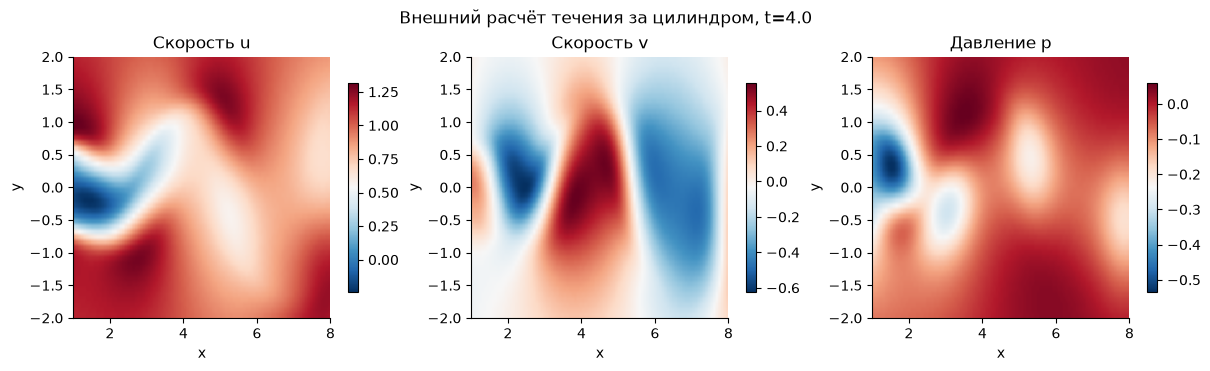

In [3]:
fields, manifest = load_cylinder(ROOT/"data"/"processed")
external = momentum_from_fields(**fields)
synthetic, synthetic_fields = taylor_green()
print("Внешние поля (t,y,x):", fields["u"].shape)
print("Исходный SHA-256:", manifest["source_sha256"])
print("Погрешность синтетических ускорений σ:", synthetic_fields["sigma_acceleration"])
fig = plot_fields(fields)
fig.savefig(OUTPUT/"cylinder_fields.png", dpi=150)
plt.show()

## 3. Оценка распределения параметров

Обозначим конвекцию через $C=(uu_x+vu_y,uv_x+vv_y)$, лапласианы через $L=(\Delta u,\Delta v)$, наблюдаемые ускорения через $a=(u_t,v_t)$. На каждом временном блоке решаем:

$$
\widehat\theta=\arg\min_{\beta,\nu}\frac1N\left\|-\beta C+\nu L-\nabla p-a\right\|_2^2.
$$

Это линейная задача МНК: $X=[-C,L]$, $y=a+\nabla p$. `numpy.linalg.lstsq` решает её через SVD. Ограничения и регуляризатор не добавляются. Поэтому нефизические оценки, если они появляются, видны в результатах. При потере ранга расчёт останавливается, а не маскируется добавкой ε.

Первые 120 доступных кадров разбиты на **12 непересекающихся блоков по 10 кадров**. До и после интервенции блоки одинаковы. Из 12 векторов получаем:

$$
\mu=\frac1B\sum_{b=1}^B\widehat\theta_b,\qquad
\Sigma=\frac1{B-1}\sum_{b=1}^B(\widehat\theta_b-\mu)(\widehat\theta_b-\mu)^T.
$$

Распределение оценок приближённо описываем $P=\mathcal N(\mu,\Sigma)$. Это ковариация оценок между окнами, **не ковариация среднего и не байесовское апостериорное распределение**. Внешние окна могут быть зависимы, а 12 оценок мало для проверки нормальности. Эллипсы ниже описывают выбранную гауссову аппроксимацию, а не доверительные области истинных параметров.

Четыре следующих кадра пропускаем, остальные оставляем для проверки. Зазор исключает пересечение пятиузловых временных шаблонов обучающей и проверочной частей. Для проверки используем отдельную общую оценку по всем обучающим кадрам. Проверочные кадры не входят ни в эту оценку, ни в μ и Σ.

## 4. Зануление давления и KL

Основная интервенция: **p=0 на всех наблюдаемых точках**, при сохранённых u, v и наблюдаемых ускорениях. Ветви градиента давления пересчитываются, поэтому тоже становятся нулевыми. Это выключение входа вычислительной модели на фиксированных данных. Оно не является новым физически согласованным решением уравнений с нулевым давлением.

Чтобы проследить изменение, дополнительно берём $p_\alpha=(1-\alpha)p$, где $\alpha\in\{0,0.25,0.5,0.75,1\}$. Конечная точка α=1 — полное зануление по варианту. Для каждой α заново оцениваем коэффициенты на тех же блоках.

Для $P_0=\mathcal N(\mu_0,\Sigma_0)$ и $P_\alpha=\mathcal N(\mu_\alpha,\Sigma_\alpha)$:

$$
D_{KL}(P_0\Vert P_\alpha)=\frac12\left[
\operatorname{tr}(\Sigma_\alpha^{-1}\Sigma_0)
+(\mu_\alpha-\mu_0)^T\Sigma_\alpha^{-1}(\mu_\alpha-\mu_0)
-2+\log\frac{\det\Sigma_\alpha}{\det\Sigma_0}\right].
$$

KL направлена, не удовлетворяет всем аксиомам расстояния и измеряется в натах. Основное направление фиксировано: исходное распределение относительно интервенционного. Обратное направление показано для сравнения. Положительную определённость ковариаций проверяем явно.

Тейлор — Грин обучение: [0.0, 11.9] проверка: [12.4, 19.900000000000002]
Течение за цилиндром обучение: [0.2, 12.100000000000001] проверка: [12.600000000000001, 19.700000000000003]


| Данные | α | β (общая оценка) | ν (общая оценка) | KL(P₀‖Pα) | Ошибка ускорения |
|---|---:|---:|---:|---:|---:|
| Тейлор — Грин | 0 | 1.000001 | 0.010000 | 0 | 1.142% |
| Тейлор — Грин | 0.25 | 0.750001 | 0.010000 | 6.694e+09 | 1.142% |
| Тейлор — Грин | 0.5 | 0.500001 | 0.010000 | 2.677e+10 | 1.142% |
| Тейлор — Грин | 0.75 | 0.250001 | 0.010000 | 6.024e+10 | 1.142% |
| Тейлор — Грин | 1 | 0.000001 | 0.010000 | 1.071e+11 | 1.142% |
| Течение за цилиндром | 0 | 0.999429 | 0.010030 | 0 | 0.268% |
| Течение за цилиндром | 0.25 | 0.948956 | 0.008933 | 201.8 | 11.316% |
| Течение за цилиндром | 0.5 | 0.898483 | 0.007837 | 253.6 | 22.627% |
| Течение за цилиндром | 0.75 | 0.848010 | 0.006740 | 254.4 | 33.940% |
| Течение за цилиндром | 1 | 0.797537 | 0.005644 | 250 | 45.252% |

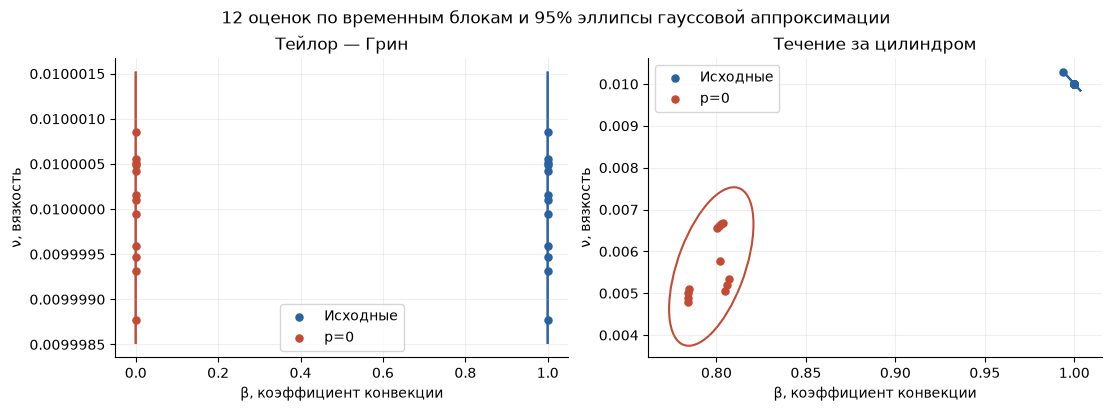

In [4]:
results = {"Тейлор — Грин": run_experiment(synthetic),
           "Течение за цилиндром": run_experiment(external)}
for name, result in results.items():
    print(name, "обучение:", result["train_time"], "проверка:", result["test_time"])
rows = ["| Данные | α | β (общая оценка) | ν (общая оценка) | KL(P₀‖Pα) | Ошибка ускорения |",
        "|---|---:|---:|---:|---:|---:|"]
for name, result in results.items():
    for row in result["rows"]:
        beta, nu = row["global_theta"]
        rows.append(f"| {name} | {row['alpha']:g} | {beta:.6f} | {nu:.6f} | {row['kl']:.4g} | {row['test_error']:.3%} |")
display(Markdown("\n".join(rows)))
fig = plot_distributions(results)
fig.savefig(OUTPUT/"parameter_distributions.png", dpi=150)
plt.show()

Распределения до и после зануления различаются. В синтетике β переходит от 1 почти к 0, а ν остаётся около 0,01. Причина видна из точного решения: конвекция уравновешена давлением. Если убрать давление и одновременно довести β до нуля, ускорение сохранится. Поэтому **одной ошибки недостаточно**, чтобы считать давление ненужным.

Внешний пример не имеет такой компенсации. После зануления меняются оба коэффициента, и остаточная ошибка растёт.

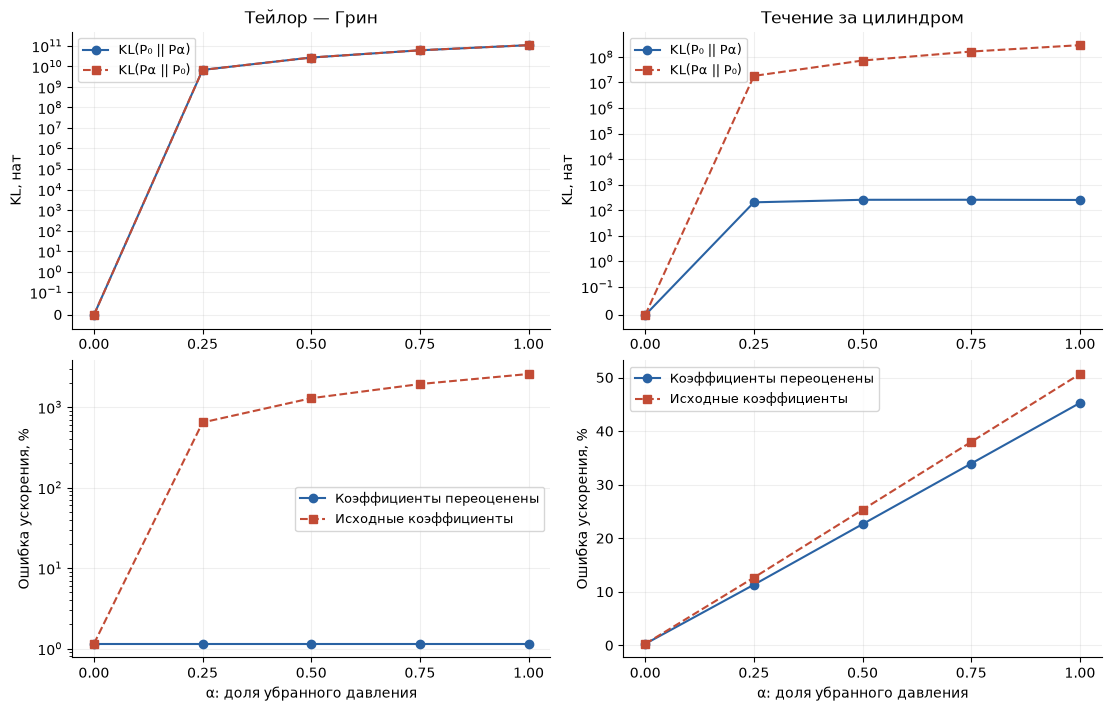

In [5]:
fig = plot_sensitivity(results)
fig.savefig(OUTPUT/"intervention_sensitivity.png", dpi=150)
plt.show()

На нижних графиках ошибка считается по ускорениям отложенных кадров:

$$
\varepsilon=\frac{\|\widehat a-a\|_2}{\|a\|_2}.
$$

Это проверка локального уравнения на новых кадрах, а не прогноз будущей траектории солвером. Сплошная линия разрешает переоценить β и ν после интервенции, пунктир сохраняет исходные коэффициенты. В обоих случаях ускорения для сравнения остаются исходными.

Огромная KL на синтетике объясняется очень узким исходным распределением β: сдвиг на единицу многократно больше его разброса. Сравнивать абсолютные KL разных наборов как универсальную «важность давления» нельзя. На внешних данных KL не обязана монотонно расти с α: меняется не только среднее, но и ковариация интервенционного распределения.

## 5. Риманово описание ковариаций

В пространстве оценок θ используем локальную метрику $g=\Sigma^{-1}$. Для изменения параметров $h$ её длина равна $\sqrt{h^T\Sigma^{-1}h}$: изменение в направлении малого естественного разброса получает больший вес. Для фиксированной Σ эта метрика постоянна; сама по себе она не создаёт кривизну пространства θ.

Положительно определённые ковариации образуют пространство SPD(2). На нём задаём аффинно-инвариантную метрику:

$$
\langle H,K\rangle_\Sigma=\operatorname{tr}(\Sigma^{-1}H\Sigma^{-1}K).
$$

Её геодезическая между ковариациями A и B:

$$
\Sigma(s)=A^{1/2}(A^{-1/2}BA^{-1/2})^sA^{1/2},\quad 0\le s\le1,
$$

а расстояние $d(A,B)=\|\log(A^{-1/2}BA^{-1/2})\|_F$. Это геометрия ковариационной части распределений. Она дополняет назначенную KL, которая также учитывает сдвиг среднего. Мы не называем эту кривую геодезической всей пары (μ,Σ) и не интерпретируем s как физическое время.

На левом графике центры эллипсов совмещены с нулём и использованы единицы исходных стандартных отклонений. Так видны именно форма и размер ковариации. Справа показаны ковариации, полученные при настоящем изменении α; они не обязаны лежать на геодезической.

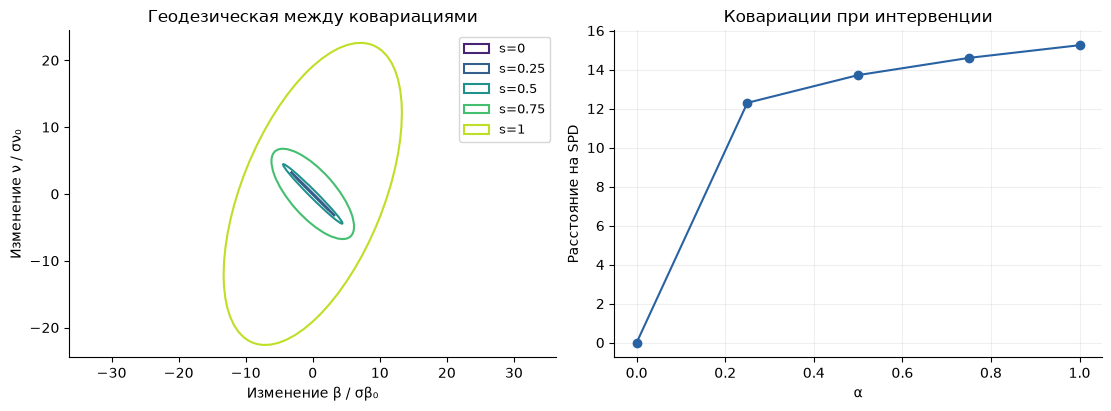

In [6]:
fig = plot_covariance_geometry(results["Течение за цилиндром"])
fig.savefig(OUTPUT/"covariance_geometry.png", dpi=150)
plt.show()

## 6. Контроль и решение о графе

Отрицательный контроль: добавить к давлению пространственно постоянную величину. Для p+3 градиент не меняется, поэтому параметры и KL должны остаться прежними. Это также проверяет, что метод анализирует действие давления через его градиент, а не произвольный нулевой уровень.

Учебное правило выбора задано до интерпретации результатов: рассматривать удаление ветви только при ошибке исходной модели ≤5%, KL≤0,1, увеличении относительной ошибки не более чем на 0,01 и положительных общих оценках β и ν. Это рабочие пороги для данного опыта, не статистический тест и не универсальная теорема. Даже выполнение всех условий даёт кандидата на упрощение, а не доказательство отсутствия физической причинности.

In [7]:
shifted_fields = dict(fields, p=fields["p"].astype(float)+3)
shifted = momentum_from_fields(**shifted_fields)
blocks = [np.arange(i*10,(i+1)*10) for i in range(12)]
original_gaussian = estimate_gaussian(results["Течение за цилиндром"]["samples"][0])
shift_gaussian = estimate_gaussian(fit_blocks(shifted, blocks))
control_kl = gaussian_kl(original_gaussian, shift_gaussian)
print(f"KL для p -> p+3: {control_kl:.3e}")
assert control_kl < 1e-8
for name, result in results.items():
    row = result["rows"][-1]
    print(name, result["decision"], "KL =", row["kl"])
output = {"variant":[2,1,2], "pressure_edges":pressure_edges,
          "constant_pressure_shift_kl":control_kl,
          "source_sha256":manifest["source_sha256"],
          "results":{name:json_result(result) for name,result in results.items()}}
(OUTPUT/"metrics.json").write_text(json.dumps(output,ensure_ascii=False,indent=2)+"\n")

KL для p -> p+3: 0.000e+00
Тейлор — Грин retain_pressure_branch KL = 107096556650.89407
Течение за цилиндром retain_pressure_branch KL = 249.96838946535493


24930

**Решение: сохранить узел давления и обе его связи с градиентами.** На синтетике удаление компенсируется потерей коэффициента конвекции, что видно по распределению параметров. На внешнем расчёте ошибка после переоценки растёт примерно с 0,27% до 45,25%, а KL(P₀‖P₁)≈250 нат.

Это вывод о выбранных данных и параметризации. Граф вычислений не становится доказанным причинным графом жидкости только из-за названия «интервенция». Плотность фиксирована, ускорения при занулении p не перегенерируются, возможную причинную связь давления и скорости модель не воспроизводит.

## 7. Вопросы к обсуждению

1. Считается ли опубликованная численная выборка Nektar++ «реальными данными» в этой работе? В черновике она отделена от нашей синтетики, но экспериментальных измерений здесь нет.
2. Для пункта 2 подходит ли метрика Σ⁻¹ и геометрия SPD-ковариаций, или требуется построить зависящую от θ метрику на самом пространстве физических параметров?
3. Допустимо ли зануление входа p на фиксированных наблюдениях как интервенция в вычислительный граф? Физически согласованный контрфактический расчёт потребовал бы другой постановки.

## Источники

- Задание «Лабораторная работа №2», вариант Дмитрия 2–1–2, распределение от 20.10.2026.
- [Иван / papayiv: исходная модель и граф](https://github.com/papayiv/NavieStocks_project/tree/66eb7bc73cd802a3249c058ad69fc59a95fbd807).
- [Raissi, Perdikaris, Karniadakis (2019). Physics-informed neural networks](https://doi.org/10.1016/j.jcp.2018.10.045), [описание примера Навье — Стокса авторами](https://maziarraissi.github.io/PINNs/), [исходные данные](https://github.com/maziarraissi/PINNs/blob/932f50a2d8ef4e80d1456bbae6887a73ff5166ef/main/Data/cylinder_nektar_wake.mat).
- [Rudy et al. (2017). Data-driven discovery of partial differential equations](https://doi.org/10.1126/sciadv.1602614): оценка коэффициентов дифференциального уравнения по наблюдаемым полям.
- [Pennec, Fillard, Ayache (2006). A Riemannian Framework for Tensor Computing](https://doi.org/10.1007/s11263-005-3222-z): аффинно-инвариантная геометрия положительно определённых матриц.
- [Zhang et al. On the Properties of Kullback-Leibler Divergence Between Multivariate Gaussian Distributions](https://arxiv.org/abs/2102.05485): формула и направленность KL для нормальных распределений.

SHA-256 и преобразования внешней выборки находятся в `data/processed/lab2_sources.json`. Код анализа — в `src/navier_lab/`, проверки — в `tests/test_navier_lab.py`. Помощь ИИ описана в `ai/`.